# Multi-Worker Kalypso: Milestone 3 Report


# Framework overview

### System design

Kalypso is a semantic query engine whose goal is to make semantic operators more efficient by scheduling them so that it gets the most out of prefix caching. The original system ran inside a single vLLM instance. Multi-worker Kalypso changes this by splitting Kalypso into a single coordinator server that sends requests over HTTP to N vLLM servers. It then uses a scheduling policy to decide which vLLM server receives each request.

#### what we added
- **Coordinator server**: This is a standalone server that is disconnected from any one vLLM instance, so that LLM calls can now be sent over HTTP independently to the N different vLLM workers. Originally, kalypso was initialized inside the vLLM startup and pinned to one instance, but we have decoupled this so that semantic queries are now sent from a standalone coordinator server which is initialized on the startup of our system, and subsequently discovers the vLLM instances.

- **Worker pool**: The worker pool is a class which helps manage the N different vLLM instances by performing a health check on every worker, and ensuring each instance is serving the same LLM model. It then reserves a KV cache for each of the different workers which is directly equal to the KV cache that the vLLM instance reserved.

- **Routing policies**: We implemented several different routing policies each having a different metric that decides which worker LLM calls are sent to
    - *Round Robin*: This is a very simple scheduling policy that rotates through the workers evenly when scheduling the next call
    - *Least_outstanding*: The scheduler looks at each vLLM worker and assigns the next call based on which has the fewest calls in flight (running + in queue)
    - *Cost aware*: This scheduler looks at the total estimated KV bytes it currently has in flight and then chooses the worker with the fewest. Essentially it is least outstanding scheduling but it chooses the worker with the cheapest total calls rather than the fewest.
    - *row_affinity*: This scheduler hopes to make the most of KV cache hits by pinning one row to a worker, and then adding all of the subsequent calls for that row on the same worker. Essentially when a row enters the pipeline, it remembers which worker it went to, and then every semantic operator that is used on that row is then run on that worker.

- **Instrumentation**: The coordinator makes a log of every LLM call, gets a list of each worker's queued and running calls every 0.5s, and records prefix cache hits across all workers.

- **Correctness Harness**: This is a harness which replaces the output of every LLM call with a deterministic one, so the output doesn’t depend on which worker served each call, letting us check that multi-worker results match single-worker Kalypso.
- **Experiment runner**: We were able to run the experiments on Modal, allowing us to observe a complete end-to-end run of the system and gather results about how well the system performed.


# 1. Experimental setup

### Hardware
- **GPUs:** 4 x NVIDIA A10 (24 GB), one vLLM worker per GPU.
- **Host:** one Modal container; coordinator and workers on the same machine, talking over localhost HTTP.
- **CPU and RAM:** not set explicitly. Modal defaults apply (request of 0.125 CPU cores and 128 MiB, soft CPU limit of 16.125 cores, no explicit memory limit), so actual use depended on the host.
- **Model:** Qwen2.5-7B-Instruct, a full copy on each GPU, no tensor parallelism.
- **vLLM settings:** prefix caching on, `gpu_memory_utilization` 0.95, `max_model_len` 32,768.
- **KV cache per worker:** 98,560 tokens (`worker_0.log`); peak use in our runs was 52 to 64%.
- **vLLM version:** upstream wheel `0.13.0rc5.dev1` (base commit `2c0ee0fde8db447bd6e7d3ea0d49070661a243fa`) with the fork's Python code installed on top.
- **Software environment:** image `nvidia/cuda:12.8.1-devel-ubuntu22.04`, Python 3.12; torch as pinned by the vLLM wheel.
- **Kalypso commits:** `91e770ea7` (main sweep) and `7ace5e7e0` (ContractNLI rerun with source-row logging).
- **Decoding:** greedy; frequency and repetition penalties off; `SemMap` retry limit 1,024 tokens.
- **Timing:** wall time around the query POST, excluding startup, data preparation and prefix cache reset.
- **Repetitions:** 3 per policy and workload (4 policies x 3 workloads x 3 reps = 36 timed runs).
- **Run order and resets:** fixed order (policy, then workload, then repetition), with a configuration's three reps run back to back. No warm-up run. Workers start once; the prefix cache is reset on every worker, and a fresh coordinator is started, before each run.

### Workloads
**FEVER**
- 500 fact-checking claims, taken as the first 500 of the 1,000-claim FEVER CSV in the repo, in record ID order.
- Pipeline: filter (is the claim about a specific person, place or work?), then map (SUPPORTED or REFUTED, with a one-sentence reason), then aggregate (summarize the most common refutation reasons).
- About 750 LLM calls per query: 500 filter calls, 248 map calls and 7 aggregate calls. About half the claims (248 of 500, 49.6%) pass the filter.
- Prompts are short: filter and map calls average about 150 tokens (p99 179). The 7 aggregate calls are much longer, averaging about 6,000 tokens and reaching about 7,800. Outputs average 12 tokens per call.

**MEDEC**
- 300 clinical notes, taken as the first 300 of the official `MEDEC-TrainingSet-1000.csv`.
- Pipeline: filter (does the note contain a medical error?), then map (ID of the erroneous sentence), then map (corrected sentence).
- About 680 LLM calls per query: 300 filter calls and 378 map calls. 189 of the 300 notes (63%) pass the filter, and each passing note gets 2 map calls.
- Prompts average 668 tokens (median 641, p99 1,185). Outputs average 10 tokens per call.

**ContractNLI**
- 200 contracts, each joined with 17 hypotheses, taken as the first 200 of the 423 contracts in the official ContractNLI `train.json`, in source order.
- Pipeline: filter (is it a valid contract?), then join each contract with all 17 hypotheses, then filter (does the contract entail the hypothesis?), then map (explain the entailment).
- About 4,430 LLM calls per query: 200 validity filter calls, 3,400 hypothesis filter calls (200 x 17) and 834 map calls. All 200 contracts pass the validity filter, and 834 of the 3,400 contract-hypothesis pairs (24.5%) pass the entailment filter and reach the map. That is about 22 calls per contract.
- Prompts average 2,049 tokens (median 1,913, p99 5,855, range 474 to 8,463). Outputs average 8 tokens per call.

Each workload uses the first N rows of its source file in file order. There is no random sampling, so no seed applies. Counts are from one round_robin run; greedy decoding makes them nearly identical across policies.



### Protocol:
- Each policy and workload combination was run 3 times. Every worker's prefix cache is reset before each run. Completion time is measured from query submission to the final result. Sweep `20261102-114247` (commit `91e770ea7`, 36 runs) is used throughout; sweep `20261102-154922` (commit `7ace5e7e0`, ContractNLI only, 1 repetition) adds the source row of each joined call for the per-contract table in Section 4.

- Results are preliminary: one worker count, three repetitions, and a smaller model than the reference paper. Deviations are listed in `DEVIATIONS.md`.

### Summary

- row_affinity had the lowest mean completion time on every workload: 1.63× faster than round_robin on ContractNLI and 1.42× on MEDEC. FEVER differences were within run-to-run variance.
- The gain comes from prefix-cache reuse, not load balance. On ContractNLI, call counts and imbalance were the same across policies, while row_affinity raised the hit rate from 73.4% to 89.9% and cut recomputed prompt tokens per run from 2.42M to 0.92M.

In [ ]:
#@title Load results and check every run succeeded
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

# In Colab, read the run data from the synced Drive folder; locally, from this folder.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/multi-kalypso")
except ImportError:
    ROOT = Path.cwd()
RUN_DIR = ROOT / "20261102-114247/n4"
RERUN_DIR = ROOT / "20261102-154922/n4"  # ContractNLI rerun with source-row logging (Section 4)
POLICIES = ["round_robin", "least_outstanding", "cost_aware", "row_affinity"]
WORKLOADS = ["fever", "medec", "contract_nli"]


def flat(df):
    """Show a table with one header row and plain row labels (no merged or stacked labels)."""
    df = df.copy()
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [" ".join(map(str, c)) for c in df.columns]
    df = df.reset_index()
    df.columns.name = None
    return df.set_index(df.columns[0]).rename_axis(None)


results = pd.read_csv(RUN_DIR / "results.csv")
results["policy"] = pd.Categorical(results.policy, POLICIES, ordered=True)
results["workload"] = pd.Categorical(results.workload, WORKLOADS, ordered=True)
# Successful reps out of attempted, per policy and workload.
flat(results.pivot_table(index="policy", columns="workload", values="status", observed=True,
                         aggfunc=lambda s: f"{(s == 'ok').sum()}/{len(s)}"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,fever,medec,contract_nli
round_robin,3/3,3/3,3/3
least_outstanding,3/3,3/3,3/3
cost_aware,3/3,3/3,3/3
row_affinity,3/3,3/3,3/3


## 2. Query completion time

Wall-clock time from query submission to final result. Points are repetitions; bars are means.

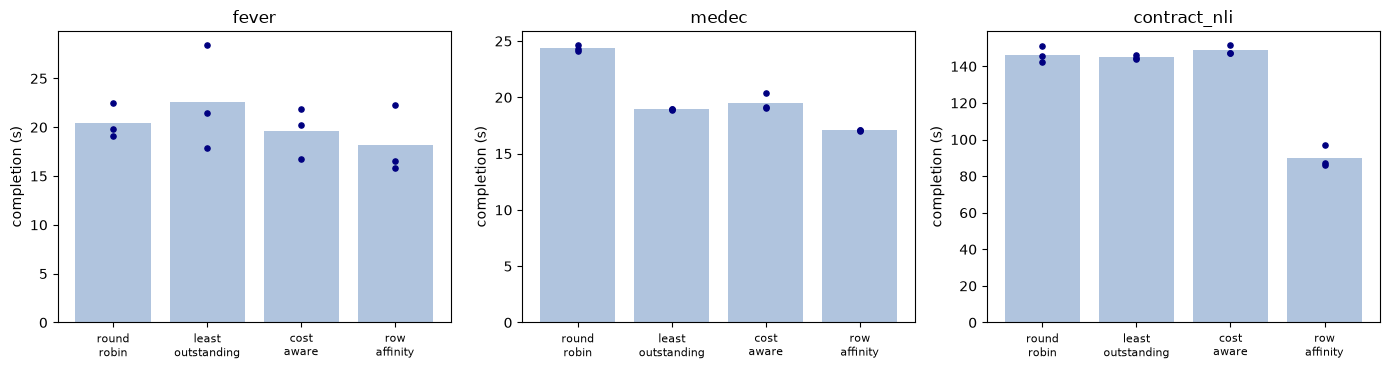

In [ ]:
#@title Plot completion time per rep
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (wl, df) in zip(axes, results.groupby("workload", observed=True)):
    means = df.groupby("policy", observed=True).completion_s.mean()
    ax.bar(range(len(means)), means, color="lightsteelblue")
    for i, p in enumerate(means.index):
        ax.scatter([i] * 3, df[df.policy == p].completion_s, color="navy", s=14, zorder=3)
    ax.set_xticks(range(len(means)), [p.replace("_", "\n") for p in means.index], fontsize=8)
    ax.set_title(wl)
    ax.set_ylabel("completion (s)")
fig.tight_layout()
plt.show()

In [ ]:
#@title Table: mean ± std completion time (s) and speedup over round_robin
means = results.pivot_table(index="policy", columns="workload", values="completion_s", observed=True)
stds = results.pivot_table(index="policy", columns="workload", values="completion_s", observed=True, aggfunc="std")
speedup = means.loc["round_robin"] / means
flat(means.round(1).astype(str) + " ± " + stds.round(1).astype(str) + " (" + speedup.round(2).astype(str) + "×)")

,fever,medec,contract_nli
round_robin,20.5 ± 1.8 (1.0×),24.3 ± 0.3 (1.0×),146.5 ± 4.5 (1.0×)
least_outstanding,22.6 ± 5.4 (0.91×),18.9 ± 0.1 (1.29×),145.1 ± 1.2 (1.01×)
cost_aware,19.6 ± 2.6 (1.04×),19.5 ± 0.7 (1.25×),148.8 ± 2.4 (0.98×)
row_affinity,18.2 ± 3.6 (1.12×),17.1 ± 0.0 (1.42×),90.1 ± 5.9 (1.63×)


row_affinity is the only policy faster than round_robin on every workload. On ContractNLI it finished in 90.1 s against 145 to 149 s for the others. On MEDEC, where σ ≤ 0.7 s, all three alternatives beat round_robin (1.25 to 1.42×). On FEVER, policy differences (18.2 to 22.6 s) are within run-to-run variance (σ up to 5.4 s).



## 3. Load balance and call latency

To separate load balance from per-call cost, we use the per-call logs (`requests.jsonl`):
- *p95 latency*: 95th percentile of submit-to-finish time per call, including time queued at the worker (start times were not recorded).
- *imbalance*: tokens on the most-loaded worker divided by the mean per worker (1.0 is even).

In [ ]:
#@title Compute per-call metrics from requests.jsonl
def load_requests(row):
    path = RUN_DIR / row.policy / row.workload / f"rep_{row.rep}" / "requests.jsonl"
    recs = [json.loads(l) for l in path.read_text().splitlines()]
    return pd.DataFrame([r for r in recs if r["type"] == "request"])

def request_metrics(row):
    reqs = load_requests(row)
    tokens = (reqs.prompt_tokens.fillna(0) + reqs.completion_tokens.fillna(0)).groupby(reqs.worker).sum()
    return pd.Series({
        "calls": len(reqs),
        "p95_latency_s": (reqs.finish_t - reqs.submit_t).quantile(0.95),
        "imbalance": tokens.max() / (tokens.sum() / row.n_workers),
    })

metrics = pd.concat([results, results.apply(request_metrics, axis=1)], axis=1)
summary = metrics.groupby(["workload", "policy"], observed=True)[
    ["completion_s", "calls", "p95_latency_s", "imbalance"]
].mean().round(2)
flat(summary)

,policy,completion_s,calls,p95_latency_s,imbalance
fever,round_robin,20.46,755.67,3.97,1.12
fever,least_outstanding,22.57,756.33,3.52,1.15
fever,cost_aware,19.59,756.00,3.56,1.14
fever,row_affinity,18.21,756.00,3.48,1.10
medec,round_robin,24.34,678.00,9.63,1.01
medec,least_outstanding,18.93,678.00,9.56,1.03
medec,cost_aware,19.53,678.33,9.63,1.02
medec,row_affinity,17.09,678.00,9.51,1.06
contract_nli,round_robin,146.46,4433.67,18.35,1.07
contract_nli,least_outstanding,145.09,4432.67,18.42,1.10


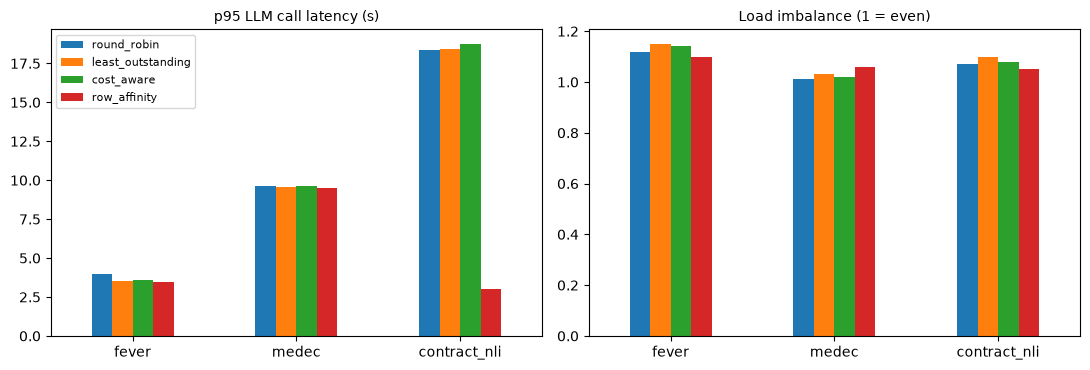

In [ ]:
#@title Plot per-call metrics
cols = {"p95_latency_s": "p95 LLM call latency (s)", "imbalance": "Load imbalance (1 = even)"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (col, title) in zip(axes, cols.items()):
    summary[col].unstack("policy").plot.bar(ax=ax, rot=0, legend=False)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

On ContractNLI, call counts (about 4,430) and imbalance (1.05 to 1.10) are similar across policies, yet p95 call latency falls from 18.4 s under round_robin to 3.0 s under row_affinity. The same calls, spread evenly, became cheaper: less prefill per call, hence less queueing. Section 4 shows where the prefill went.

## 4. Prefix-cache reuse

Per run, the coordinator records prompt tokens looked up in the prefix cache and tokens served from it, summed over workers (`QUERY_KV_STATS` in `coordinator.log`). Hit rate = reused ÷ queried; recomputed = queried − reused.

In [ ]:
#@title Table: prefix-cache hit rate and recomputed prompt tokens
def kv_stats(row):
    log = RUN_DIR / row.policy / row.workload / f"rep_{row.rep}" / "coordinator.log"
    line = [l for l in log.read_text().splitlines() if "QUERY_KV_STATS" in l][-1]
    s = json.loads(line.split("QUERY_KV_STATS", 1)[1])
    return pd.Series({
        "hit rate (%)": 100 * s["prefix_tokens_reused"] / s["prefix_tokens_queried"],
        "recomputed (k tokens)": (s["prefix_tokens_queried"] - s["prefix_tokens_reused"]) / 1e3,
    })

cache = pd.concat([results, results.apply(kv_stats, axis=1)], axis=1)
flat(cache.pivot_table(index="policy", columns="workload", observed=True,
                       values=["hit rate (%)", "recomputed (k tokens)"]).round(1))

,hit rate (%) fever,hit rate (%) medec,hit rate (%) contract_nli,recomputed (k tokens) fever,recomputed (k tokens) medec,recomputed (k tokens) contract_nli
round_robin,24.4,20.6,73.4,115.2,359.2,2418.2
least_outstanding,25.3,44.1,73.7,113.9,253.2,2389.9
cost_aware,25.5,43.6,73.3,113.6,255.6,2427.6
row_affinity,26.8,51.4,89.9,111.6,220.0,915.6


On ContractNLI, row_affinity reached an 89.9% hit rate against 73.3 to 73.7%, and recomputed 0.92M prompt tokens per run against 2.39M to 2.43M.

The prompt layout explains both numbers. The system prompt and contract text (about 1.9k of 2.05k tokens) come before the hypothesis, so a contract's ~22 calls (one validity filter, 17 hypothesis filters, about 4 maps) share a long prefix. A worker misses only on its first call for a contract. Spread over four workers, that gives (22 − 4)/22 × 0.92 ≈ 75% expected (73.4% measured); on one worker, (22 − 1)/22 × 0.92 ≈ 88% (89.9% measured). Each contract prefix is computed up to four times instead of once, hence the 2.6× difference in recomputed tokens.

**Workers per contract.** The main sweep did not log the source row of calls after the ContractNLI join (fixed in `9d2acedac`), so this table uses the rerun.

In [ ]:
#@title Table: workers per contract, completion time and hit rate (rerun)
def rerun_row(policy):
    run = RERUN_DIR / policy / "contract_nli" / "rep_1"
    recs = [json.loads(l) for l in (run / "requests.jsonl").read_text().splitlines()]
    reqs = pd.DataFrame([r for r in recs if r["type"] == "request"])
    workers = reqs.groupby("row_idx").worker.nunique()
    line = [l for l in (run / "coordinator.log").read_text().splitlines() if "QUERY_KV_STATS" in l][-1]
    s = json.loads(line.split("QUERY_KV_STATS", 1)[1])
    return {
        "workers per contract (mean)": round(workers.mean(), 2),
        "contracts on 1 worker": (workers == 1).sum(),
        "contracts on 4 workers": (workers == 4).sum(),
        "hit rate (%)": round(100 * s["prefix_tokens_reused"] / s["prefix_tokens_queried"], 1),
        "completion (s)": round(s["elapsed_seconds"], 1),
    }

pd.DataFrame([rerun_row(p) for p in POLICIES], index=POLICIES)

,workers per contract (mean),contracts on 1 worker,contracts on 4 workers,hit rate (%),completion (s)
round_robin,3.91,0,184,73.8,155.8
least_outstanding,3.91,0,183,73.9,160.1
cost_aware,3.89,0,180,73.6,157.6
row_affinity,1.00,200,0,89.9,96.1


Under row_affinity, every contract was served by one worker; under the other policies, by 3.9 on average, and 180 to 184 of 200 contracts reached all four. This matches the assignment assumed above.

**Why least_outstanding and cost_aware help on MEDEC.** A MEDEC row issues a filter call and, if it passes, one or more map calls over the same row text. The table checks whether their MEDEC speedup comes from balance or from cache reuse (mean over reps).

In [ ]:
#@title Table: MEDEC cache reuse vs load balance
def workers_per_row(row):
    return load_requests(row).groupby("row_idx").worker.nunique().mean()

med = results.workload == "medec"
evidence = pd.concat([metrics[med][["policy", "completion_s", "imbalance"]],
                      cache[med][["hit rate (%)", "recomputed (k tokens)"]]], axis=1)
evidence["workers per row"] = results[med].apply(workers_per_row, axis=1)
flat(evidence.groupby("policy", observed=True)[
    ["workers per row", "hit rate (%)", "recomputed (k tokens)", "imbalance", "completion_s"]].mean().round(2))

,workers per row,hit rate (%),recomputed (k tokens),imbalance,completion_s
round_robin,1.85,20.63,359.16,1.01,24.34
least_outstanding,1.20,44.05,253.19,1.03,18.93
cost_aware,1.25,43.55,255.64,1.02,19.53
row_affinity,1.00,51.37,220.05,1.06,17.09


Across the four policies, fewer workers per row goes with a higher hit rate, fewer recomputed tokens and a shorter completion time, while least_outstanding and cost_aware are no better balanced than round_robin. This suggests their MEDEC gain comes from cache reuse, not balance. Why they keep a row's calls together is not established; one possibility is that a row's map is submitted when its filter finishes, which frees a slot on that worker and makes it the least loaded. On FEVER the same policies also keep rows on about 1.25 workers but gain nothing, consistent with its short prompts (about 200 tokens) leaving little to reuse; FEVER hit rates were 24.4 to 26.8% for all policies.

## 5. Improving on row_affinity

row_affinity is the best policy we measured, and its gain is entirely from caching. Two questions follow: does its lead grow on larger workloads, and does it leave performance behind by ignoring load?

**Larger workloads should widen the gap.** Each worker's KV cache holds 98,560 tokens (`worker_0.log`), about 48 ContractNLI prefixes of 2k tokens. round_robin needs every active contract cached on every worker, so the cluster holds about 48 distinct contracts at once; row_affinity caches each contract once, about 190. Peak KV usage in our runs was 52 to 64%, so neither policy evicted. With more contracts in flight (the full dataset, or a larger stage budget), round_robin should start evicting and recomputing prefixes well before row_affinity does. This is a prediction we have not measured.

**row_affinity ignores load, and it shows over short time scales.** Total tokens per worker are balanced (imbalance 1.03 to 1.09), but the per-worker queue samples show bursts. A contract's 17 hypothesis filters are released together once its validity filter passes, and all land on one worker while the others may be idle. Placement also ignores contract size: prompts range from 474 to 8,463 tokens and contracts from 18 to 28 calls. The table below summarizes load over the 0.5 s queue samples:
- *load CV*: standard deviation over mean of running + queued calls across workers (0 is even);
- *idle worker-time*: fraction of worker samples with no calls while the query still had work;
- *stranded*: fraction of samples in which one worker had queued calls while another was empty.

In [ ]:
#@title Table: short-term load balance on ContractNLI (mean over reps)
def balance(row):
    path = RUN_DIR / row.policy / row.workload / f"rep_{row.rep}" / "requests.jsonl"
    q = pd.DataFrame([r for r in map(json.loads, path.read_text().splitlines()) if r["type"] == "queue_sample"])
    q = q.sort_values("t").reset_index(drop=True)
    q["round"] = q.index // row.n_workers  # one sample per worker per polling round
    load = q.pivot_table(index="round", columns="worker", values="running") + \
           q.pivot_table(index="round", columns="worker", values="waiting")
    waiting = q.pivot_table(index="round", columns="worker", values="waiting")
    busy = load.sum(axis=1) > 0
    return pd.Series({
        "load CV": (load.std(axis=1) / load.mean(axis=1))[load.mean(axis=1) >= 1].mean(),
        "idle worker-time (%)": 100 * (load[busy] == 0).values.mean(),
        "stranded (%)": 100 * ((waiting.max(axis=1) > 0) & (load.min(axis=1) == 0))[busy].mean(),
    })

cnli = results[results.workload == "contract_nli"]
flat(pd.concat([cnli, cnli.apply(balance, axis=1)], axis=1)
     .groupby("policy", observed=True)[["completion_s", "load CV", "idle worker-time (%)", "stranded (%)"]].mean().round(2))

,completion_s,load CV,idle worker-time (%),stranded (%)
round_robin,146.46,0.14,0.66,0.15
least_outstanding,145.09,0.14,1.25,0.30
cost_aware,148.77,0.13,1.41,0.00
row_affinity,90.12,0.80,5.09,5.42


Under row_affinity, load across workers varies about six times more than under round_robin (CV about 0.8 against 0.14). Workers sit empty for 5.1% of worker-time, and in 5.4% of samples a worker holds queued calls while another is empty (under 1.5% for every other policy). round_robin almost never idles a worker, but it pays for that by computing each prefix up to four times.

Moving a call off its row's worker costs one prefix recomputation. Taking the 1.5M extra prompt tokens round_robin recomputes and the 56 s it loses on four workers gives about 6.7k tokens/s per worker, so roughly 0.3 s for a 2k-token contract. Moving a queued call therefore pays off only when it would otherwise wait longer than its prefix takes to recompute elsewhere. At this scale the headroom is small: with about 5% of worker-time idle, filling those gaps would save on the order of 5%. It should grow with skewed contract sizes, larger fan-out per row, or fewer rows than workers can hold. The next policy should keep row_affinity's placement and spill only in these cases.

### Combining cache affinity and load

The data above says the next policy should keep row_affinity's cache reuse and add load awareness. Zhang et al. ([LMetric, OSDI '26](https://www.usenix.org/system/files/osdi26-zhang-dingyan.pdf)) compare the ways this has been done (weighted sums, load filters and latency simulators) and find that a simple product of the two signals performs best without any tuning. We adopt their rule rather than re-evaluating the alternatives, which would need per-workload tuning sweeps we do not have the compute or time for.

The rule sends each call to the worker with the lowest `P_w × BS_w`. `P_w` is the prefill tokens worker w would have queued if the call were sent there, after subtracting its cached prefix; `BS_w` is the worker's batch size including the new call.

**Proposed policy (`prefix_load`).** The coordinator cannot see worker caches, so it estimates `P_w` from its own routing history: if w served an earlier call of the same row, only the non-shared suffix (about 150 tokens on ContractNLI) is new; otherwise the full prompt (about 2,050). A call therefore leaves its row's worker only when that worker has about 14 times the batch of another. That matches the stranded cases above (row_affinity queues up to 20 to 44 calls on one worker while another is empty) and keeps row_affinity's placement otherwise.


**Experiment design.** Every experiment compares `prefix_load` against all four existing policies (`round_robin`, `least_outstanding`, `cost_aware`, `row_affinity`). Each configuration is run 5 times instead of 3 to tighten the run-to-run spread. The prefix cache is reset before every run, and the correctness harness checks that every policy produces the same outputs.

**Success criteria.**
- Experiment 1: `prefix_load` is within the min-to-max spread of `row_affinity` and faster than every per-call policy.
- Experiments 2 and 3: the mean completion time of `prefix_load` beats `row_affinity` by more than the larger of the two policies' min-to-max spreads, and its cache hit rate stays within 3 percentage points of `row_affinity`.
- Experiment 4: the speedup of `prefix_load` over `round_robin` holds or grows as workers are added.

If none of these holds, we report that the headroom is below noise, which is what the analysis above predicts for the current setup.

**Experiment 1: current setup**
- What is different: nothing changes from the main sweep. We run `prefix_load` against all existing policies on FEVER, MEDEC and ContractNLI.
- Hypothesis: `prefix_load` is very similar to `row_affinity`, since we calculated the headroom to be only about 5%.

**Experiment 2: memory pressure**
- What is different: we run the same experiment on ContractNLI, but limit each worker's KV cache to 50% and 25% of the maximum (for example by lowering `gpu_memory_utilization`). The main sweep used 52 to 64% of the cache at peak, so these caps force prefixes to be evicted.
- Hypothesis: `round_robin` takes the biggest performance hit because it has to recompute prefixes. `row_affinity` has many more backed-up requests and idle workers. `prefix_load` gets the best of both by recognizing when it needs to switch workers while requests wait in the queue.

**Experiment 3: skewed rows**
- What is different: we build ContractNLI workloads with a deliberately uneven length mix, choosing contracts across the observed range of 474 to 8,463 tokens, plus a variant where the longest contracts arrive first.
- Hypothesis: `row_affinity` stalls heavily on long contract rows and leaves long queues waiting while other workers are available. `prefix_load` recognizes when to switch over and reduces latency by using the idle workers more effectively.

**Experiment 4: more workers**
- What is different: we run the same ContractNLI workload on 1, 2 and 4 workers, and on more if we can get the resources.
- Hypothesis: `round_robin` takes the biggest performance hit again, because the probability that a call's prefix is cached falls as the number of workers grows. If everything else stays the same, `prefix_load` has similar metrics to `row_affinity`. This also shows how well the overall system scales.

**Metrics**
- Speed: completion time and p95 latency.
- Cache reuse: prefix cache hit rate and recomputed tokens.
- Load: idle worker time.
- Routing: the number of times `prefix_load` routed a row away from its previously assigned worker.







## 6. Limitations and future work

**Limitations.** All runs are in a low memory-pressure regime (peak KV usage 52 to 64%), so the results do not show how the policies behave once prefixes are evicted (Section 5).

Runs execute in a fixed order (policy, then workload, then repetition), so the three repetitions of each configuration run back to back. Slow drift on the host would therefore not be averaged across policies.

**Future work.**
- Implement and evaluate `prefix_load` (Section 5).
- Vary KV-cache capacity (`gpu_memory_utilization`) and the number of active contracts.
- Record call start times to separate queueing from service time, and per-worker prefix-cache counters.
- Repeat at more worker counts, and with more repetitions for FEVER.

## Appendix: workload statistics

Call counts, filter selectivity and prompt lengths for each workload, measured from one `round_robin` run (rep 1) per workload. These are the numbers quoted in the Workloads section.

In [ ]:
#@title Per-workload call counts and prompt lengths
def workload_stats(workload):
    row = results[(results.policy == "round_robin") & (results.workload == workload)].iloc[0]
    r = load_requests(row)
    r = r[r.status == "ok"]
    p99 = lambda s: s.quantile(0.99)
    by_stage = (r.groupby(["stage", "operator"])
                  .agg(calls=("request_id", "size"),
                       rows=("row_idx", "nunique"),
                       prompt_mean=("prompt_tokens", "mean"),
                       prompt_p50=("prompt_tokens", "median"),
                       prompt_p99=("prompt_tokens", p99),
                       completion_mean=("completion_tokens", "mean"))
                  .round(1))
    overall = pd.Series({
        "calls": len(r),
        "prompt_mean": r.prompt_tokens.mean(),
        "prompt_p50": r.prompt_tokens.median(),
        "prompt_p99": p99(r.prompt_tokens),
        "completion_mean": r.completion_tokens.mean(),
    }).round(1)
    return by_stage, overall

for w in WORKLOADS:
    by_stage, overall = workload_stats(w)
    print("=====", w)
    display(by_stage)
    print(overall.to_string())

===== fever


calls  rows  prompt_mean  prompt_p50  prompt_p99  \
stage operator                                                      
1     SemFilter    500   500        151.8       151.0       166.0   
      SemMap       248   248        139.8       139.0       153.5   
2     SemAgg         7     0       6023.3      7647.0      7805.1   

                 completion_mean  
stage operator                    
1     SemFilter              2.7  
      SemMap                27.7  
2     SemAgg               131.7

calls              755.0
prompt_mean        202.3
prompt_p50         149.0
prompt_p99         179.0
completion_mean     12.1
===== medec


calls  rows  prompt_mean  prompt_p50  prompt_p99  \
stage operator                                                      
1     SemFilter    300   300        679.5       652.0      1157.7   
      SemMap       378   189        657.9       631.5      1184.7   

                 completion_mean  
stage operator                    
1     SemFilter              3.0  
      SemMap                15.7

calls               678.0
prompt_mean         667.5
prompt_p50          641.0
prompt_p99         1184.7
completion_mean      10.1
===== contract_nli


calls  rows  prompt_mean  prompt_p50  prompt_p99  \
stage operator                                                      
1     SemFilter    200   200       1971.6      1830.0      5800.3   
2     SemFilter   3400     1       2033.0      1893.5      5873.1   
      SemMap       834     1       2132.4      2107.0      5270.7   

                 completion_mean  
stage operator                    
1     SemFilter              2.9  
2     SemFilter              2.3  
      SemMap                31.7

calls              4434.0
prompt_mean        2048.9
prompt_p50         1913.0
prompt_p99         5854.7
completion_mean       7.9


## References

Zhang, D., Han, J., Zhang, K., Wei, X., Shen, S., Fang, C., Yu, W., Zhou, J., and Chen, R. (2026). Simple is Better: Multiplication May Be All You Need for LLM Request Scheduling. In *20th USENIX Symposium on Operating Systems Design and Implementation (OSDI 26)*, pp. 55-73. https://www.usenix.org/system/files/osdi26-zhang-dingyan.pdf